In [2]:
# Put imports here
import numpy as np
import scipy as sp
from scipy import stats
import matplotlib as mp
import matplotlib.pyplot as plt
import mp2lib as ml

SEED = 1320312820 # drawn 2026-10-29, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

## Step 1
Work with four distributions: uniform on [0,1], exponential with rate 1, standard Gaussian, and Rayleigh with scale 1.

### 1. For each, write the CDF and the PDF in a Markdown cell, and state the support.

*Uniform [0,1]:*

PDF:
$$
f_X(x) =
\begin{cases}
    \frac{1}{b-a} & \text{if }\text{ } a \leq x \leq b
    \\ 0, & \text{else}
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) =  
\begin{cases}
    0 & \text{if }\text{ } x < 0
    \\ x & \text{if }\text{ } 0 \leq x \leq 1 
    \\ 1 & \text{if }\text{ } x \geq 1
\end{cases}
$$

*Exponential with rate 1:*

PDF: 
$$
f_X(x) =
\begin{cases}
    e^{-x} & \text{if }\text{ } x < 0
    \\ 0 & \text{else }
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) = 
\begin{cases}
    1 - e^{-x} & \text{if }\text{ } x < 0
    \\ 0 & \text{else }
\end{cases}
$$

*Standard Gaussian:*

PDF: 
$$
f_Z(z) = \frac{1}{\sqrt{2\pi}} e^{-z^2/2} \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

CDF:

$$
\Phi(z) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{z} e^{-u^2/2} \,du  \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

*Rayleigh with scale 1:*

PDF: 
$$
f_X(x;\sigma=1) = x e^{-x^2/(2)} \ \ \text{for } x \geq 0
$$

CDF:

$$
F_X(x;\sigma=1) = 1 - e^{-x^2/(2)} \ \ \text{for } x \ \epsilon \ [0,\infty)
$$

### 2. Generate 10<sup>5</sup> samples of each with the library generators.

In [48]:
# Generating 10^5 samples of each funciton
n = 10**5

unif = rng_1.random(size=n)
expo = rng_1.exponential(scale=1.0, size=n)
gau = rng_1.standard_normal(size=n)
ray = rng_1.rayleigh(scale=1.0, size=n)

print("Uniform [0,1]\t\t\tExponential w/ Rate 1\t\tStandard Gaus\t\t\tRayleigh scale 1")
print("----------------------------------------------------------------------------------------------------------------------")
for i in range(0,n,1): 
    print(unif[i], end="\t\t")
    print(expo[i], end="\t\t")
    print(gau[i], end="\t\t")
    print(ray[i])

Uniform [0,1]			Exponential w/ Rate 1		Standard Gaus			Rayleigh scale 1
----------------------------------------------------------------------------------------------------------------------
0.3368828838571424		1.7187701748829167		-0.5901478330513703		0.8028398189948927
0.8716387285861463		1.3648179704754222		-0.18361871998121818		1.314622273341582
0.5873301948251933		1.68873709321894		0.5877718101890562		0.6130165415768344
0.27723168789831465		0.4736410343457573		0.7507299734231844		1.084874917236633
0.4622340357198905		0.17820073634294492		0.2927738877476009		1.2824430488574359
0.9633044136993598		2.5026646821185654		0.7043891668081735		0.5962017623949843
0.06879983831479142		0.2600099157069083		0.6029881590123235		1.5933046466815326
0.3037450570872249		1.5344808169210298		0.5428539514374754		1.2172767720846203
0.06685245268678197		1.722094159703503		-0.68991732370299		0.3445923356496797
0.5296299339121647		0.08194214668595412		-0.34116846416237406		0.7354742966833536
0.4852455257354

### 3. Plot the empirical CDF against the analytic CDF for each.

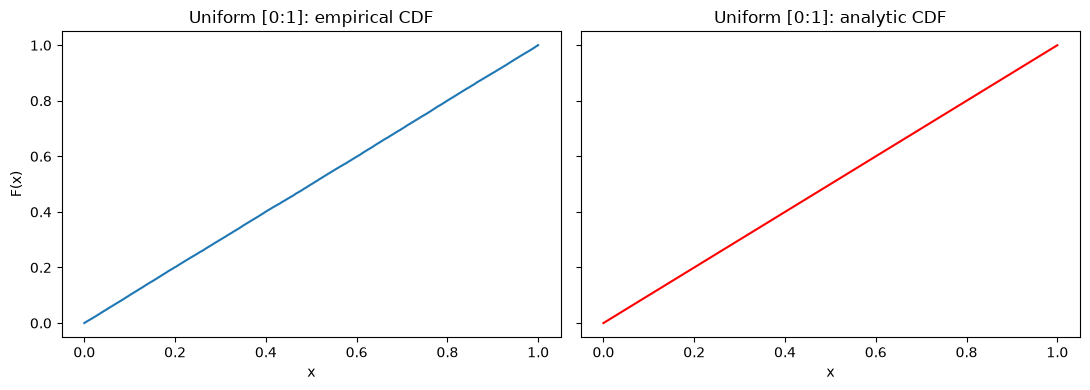

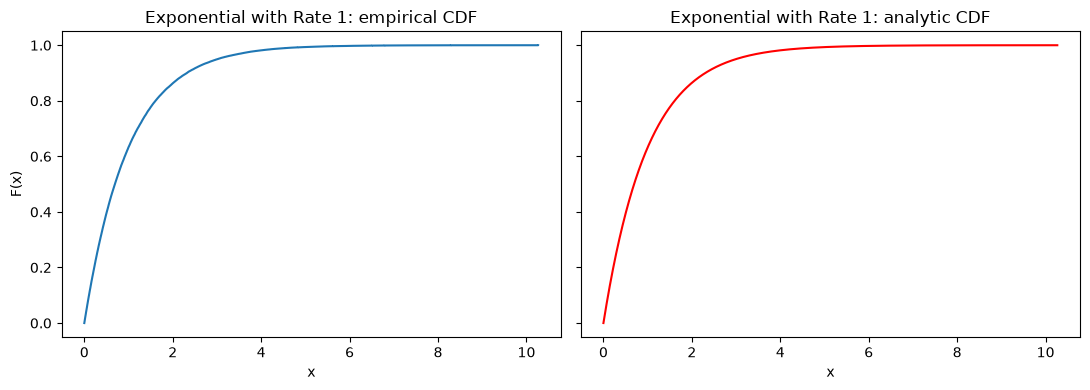

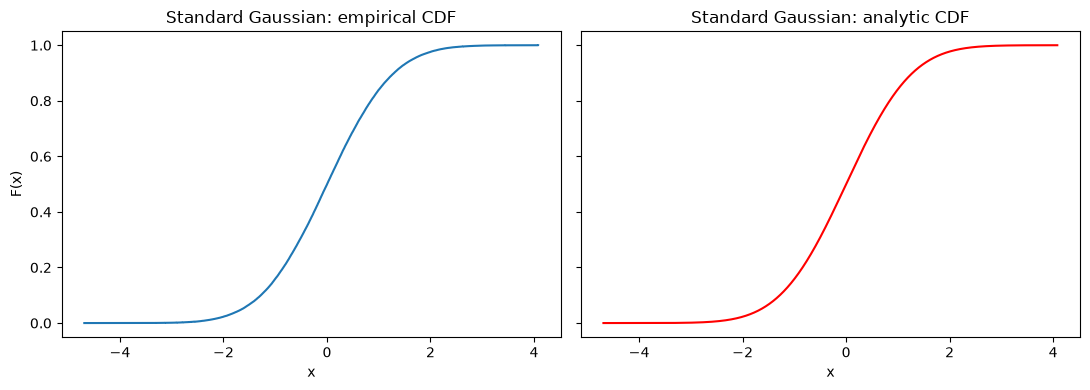

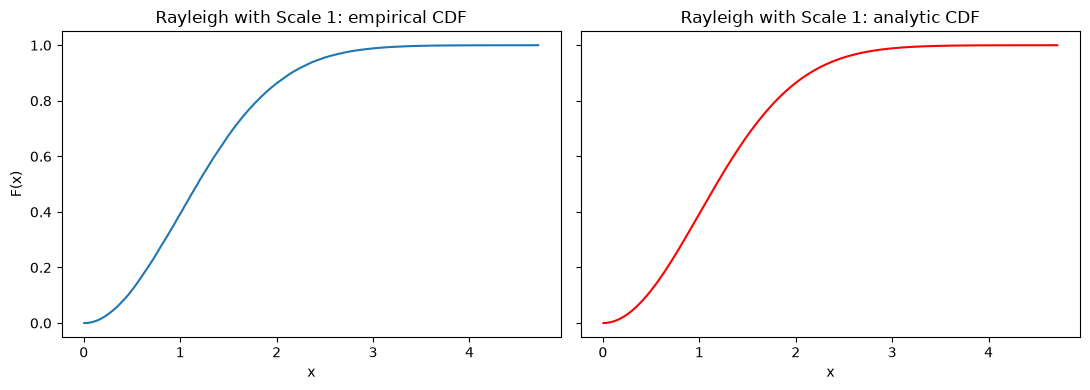

In [ ]:
# name -> (samples, analytic CDF)
dists = {
    "Uniform [0:1]":            (unif,      stats.uniform.cdf),
    "Exponential with Rate 1":  (expo,   stats.expon.cdf),
    "Standard Gaussian":        (gau,       stats.norm.cdf),
    "Rayleigh with Scale 1":    (ray,       stats.rayleigh.cdf),
}

def ecdf(x):
    xs = np.sort(x)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    return xs, ys

for name, (x, cdf) in dists.items():
    xs, ys = ecdf(x)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

    # left: empirical CDF
    ax1.step(xs, ys, where="post")
    ax1.set_title(f"{name}: empirical CDF")
    ax1.set_xlabel("x")
    ax1.set_ylabel("F(x)")

    # right: analytic CDF
    ax2.plot(xs, cdf(xs), color='r')
    ax2.set_title(f"{name}: analytic CDF")
    ax2.set_xlabel("x")

    fig.tight_layout()
    plt.show()

### 4. Plot a normalized histogram against the analytic pdf for each.

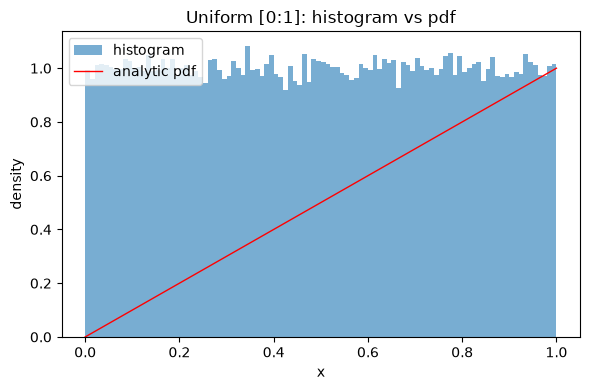

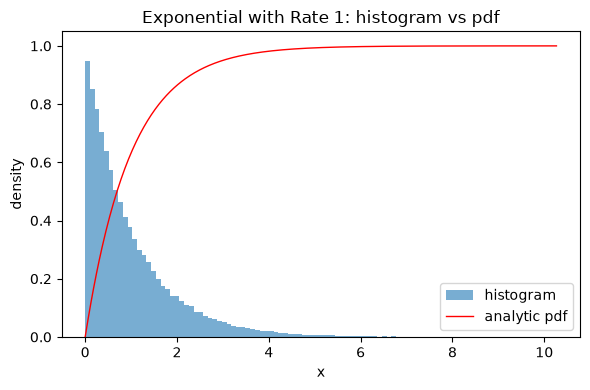

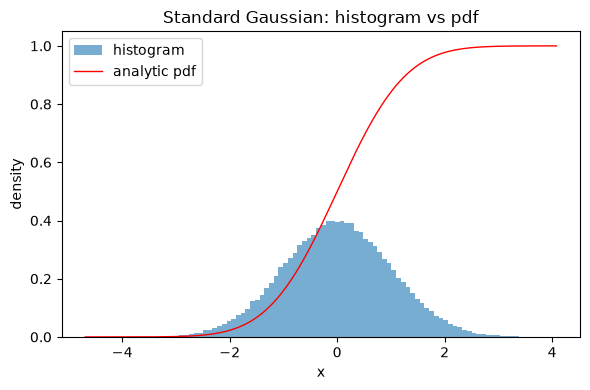

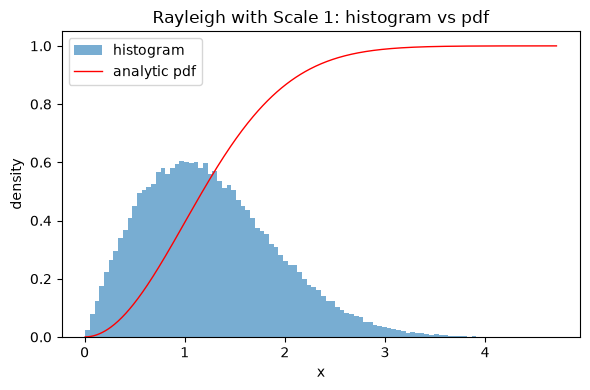

In [50]:
for name, (x, pdf) in dists.items():
    grid = np.linspace(x.min(), x.max(), 500)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(x, bins=100, density=True, alpha=0.6, label="histogram")
    ax.plot(grid, pdf(grid), "r-", lw=1, label="analytic pdf")
    ax.set_title(f"{name}: histogram vs pdf")
    ax.set_xlabel("x")
    ax.set_ylabel("density")
    ax.legend()

    fig.tight_layout()
    plt.show()

### 5. Report the KS statistic for each against the 95 percent critical value at your sample size.

In [ ]:
from scipy.stats import kstest, ksone

# Calculating KS statistic and p values
uniform_ks_stat = ml.ks_statistic(unif, stats.uniform.cdf)
exponential_ks_stat= ml.ks_statistic(expo, stats.expon.cdf)
gaussian_ks_stat = ml.ks_statistic(gau, stats.norm.cdf)
rayleigh_ks_stat = ml.ks_statistic(ray, stats.rayleigh.cdf)

# Calculating the 95% critical value
crit_val = ksone.ppf(0.95, n)

print(f"Critical Value for 95% (Exact): {crit_val}\n")

print("KS Statistics:\n---------------------------------------------")

print(f"Empirical Samples of Uniform [0:1]:          {uniform_ks_stat}")
print(f"Empirical Samples of Exponential w/ Rate 1:  {exponential_ks_stat}")
print(f"Empirical Samples of Standard Gaussian:      {gaussian_ks_stat}")
print(f"Empirical Samples of Rayleigh w/ Rate 1:     {rayleigh_ks_stat}\n")

print(f"KS Statistics against the 95% Critical Value of {crit_val}:")

if(uniform_ks_stat <= crit_val):
    print(f"Uniform [0:1] KS Statistic of {uniform_ks_stat} is less than the 95% critical value." +
          f"\nThe sample data does follow the theoretical uniform distribution")

Critical Value for 95%: 0.003868559112926622
KS Statistics:
---------------------
Uniform [0:1]:          0.001741254971295958
Exponential w/ Rate 1:  0.0022155212891404874
Standard Gaussian:      0.0030138233942974546
Rayleigh w/ Rate 1:     0.002908801560022156


### 6. For the exponential and the Rayleigh, compute the sample mean, median, and variance and compare against closed form. State all six closed forms.

### 7. The exponential mean and median differ by a factor of about 1.44 while the Gaussian mean and median coincide. Explain in two sentences what property of the density causes that.

## Step 2

## Step 3

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B